# alberto_raw_text pipeline

- Finetunes Alberto model
Uses original anonymized_text unchanged:
- no URL/mention removal, emoji separation, or vocabulary additions.

Libraries import

In [1]:
%pip install emoji

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 24.3 MB/s  0:00:00


In [2]:
import pandas as pd
import re
import collections
import gc
import matplotlib.pyplot as plt


In [3]:
import re
import regex
import emoji


In [4]:
import html
import re
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

from transformers import AddedToken
from transformers import EarlyStoppingCallback

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Import data

In [6]:
training_textual_path = '/content/drive/MyDrive/master_unipa/training_textual.csv'
training_contextual_path = '/content/drive/MyDrive/master_unipa/training_contextual.csv'

test_textual_path = '/content/drive/MyDrive/master_unipa/test_textual_gold.csv'
test_contextual = '/content/drive/MyDrive/master_unipa/test_contextual.csv'

In [7]:
df_train = pd.read_csv(training_textual_path)
df_train_contextual = pd.read_csv(training_contextual_path)

df_test = pd.read_csv(test_textual_path)
df_test_contextual = pd.read_csv(test_contextual)

## 1. Exploratory Data Analysis

In [8]:
df_train.head(2)
display(df_train.head(3))
display(df_train.shape)
display(df_train.label.value_counts())
display(df_train.dataset.value_counts())

print(f'Are tweets ids unique? {df_train["anonymized_tweet_id"].is_unique}')
print(f'Are there any repeated lines? {df_train.duplicated().any()}')


,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics
2,817917484817935,Il #m5s ha votato contro le #unionicivili addu...,1,training_politics


(5600, 4)

,count
label,
0,3456
1,2144


,count
dataset,
training_politics,5600


Are tweets ids unique? True
Are there any repeated lines? False


In [9]:
print(df_test["dataset"].value_counts())

df_train = df_train.loc[
    df_train["dataset"].eq("training_politics")
].copy()

df_test = df_test.loc[
    df_test["dataset"].eq("test_politics")
].copy()

assert len(df_train) == 5600
assert len(df_test) == 1400

dataset
test_religious    3000
test_politics     1400
Name: count, dtype: int64


In [10]:
df_test["dataset"].value_counts()

,count
dataset,
test_politics,1400


In [11]:
df_test.head(2)

,anonymized_tweet_id,anonymized_text,label,dataset
0,424801448454884,questo anno #babbonatale portato giocattolo it...,1,test_politics
1,775194088981616,Adesso che in mezzo alla strada grazie al verg...,1,test_politics


In [12]:
df_train["anonymized_tweet_id"].is_unique

True

In [13]:
df_train['anonymized_tweet_id'].duplicated().any()

np.False_

In [14]:
df_train_contextual.head(2)
display(df_train_contextual.head(3))
display(df_train_contextual.shape)
display(df_train_contextual.columns)
display(df_train.dataset.value_counts())
# Contextual rows are aligned by tweet ID when needed, not by row order.

print(f'Are tweets ids unique? {df_train_contextual["anonymized_tweet_id"].is_unique}')
print(f'Are there any repeated lines? {df_train_contextual.duplicated().any()}')

,anonymized_tweet_id,created_at,retweet_count,favorite_count,source,is_reply,is_retweet,is_quote,anonymized_user_id,user_created_at,statuses_count,followers_count,friends_count,anonymized_description,dataset
0,217874450618134,2018-08-11,0.0,6.0,"<a href=""http://twitter.com/download/iphone"" r...",1.0,0.0,0.0,8.868893e+14,2018-04-01,554.0,748.0,753.0,Avete presente quegli stereotipi sui siciliani...,training_politics
1,360042217507605,2018-11-08,154.0,448.0,"<a href=""http://twitter.com/download/iphone"" r...",0.0,0.0,0.0,2.570741e+14,2011-10-26,35043.0,10838.0,4535.0,Prof di latino e Deputata PD.Ama lo sport la R...,training_politics
2,817917484817935,2018-11-10,195.0,638.0,"<a href=""http://twitter.com/download/iphone"" r...",0.0,0.0,0.0,6.908473e+14,2009-09-24,139750.0,7971.0,1866.0,"Medico, appassionato di Cinema d'Autore, Music...",training_politics


(5600, 15)

Index(['anonymized_tweet_id', 'created_at', 'retweet_count', 'favorite_count',
       'source', 'is_reply', 'is_retweet', 'is_quote', 'anonymized_user_id',
       'user_created_at', 'statuses_count', 'followers_count', 'friends_count',
       'anonymized_description', 'dataset'],
      dtype='object')

,count
dataset,
training_politics,5600


Are tweets ids unique? True
Are there any repeated lines? False


### Basic statics

count    5600.000000
mean      190.924464
std        75.138851
min        24.000000
25%       127.000000
50%       196.000000
75%       263.000000
max       740.000000
Name: anonymized_text, dtype: float64


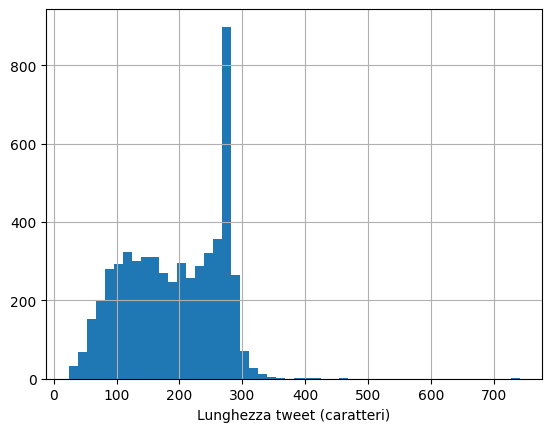

In [15]:
# Statistiche descrittive senza modificare il testo.
print(df_train['anonymized_text'].str.len().describe())
df_train['anonymized_text'].str.len().hist(bins=50)
plt.xlabel('Lunghezza tweet (caratteri)')
plt.show()

Eliminate double white spaces

In [16]:
df_train.head(2)

,anonymized_tweet_id,anonymized_text,label,dataset
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics


In [17]:
df_train.columns

Index(['anonymized_tweet_id', 'anonymized_text', 'label', 'dataset'], dtype='object')

### Load and validate data

## Raw text input
The cleaning function below is retained only to build the common deduplication key. load_split uses anonymized_text unchanged.

In [18]:
import re

def clean_text(text):
    pattern = (
        r"https?://\S+"   # URL starting by http:// ou https://
        r"|www\.\S+"      # URL starting by www.
        r"|\[url\]"       # [url] ou [URL], [] included in the pattern
        r"|(?<!\w)@\w+"   # user mention/tag (@unknown, @500068400229841, @user_123)
                         # (?<!\w) : avoids @ preceded by a letter or digit like in a e-mail adress

    )

    # found elements replaced by a space
    text = re.sub(pattern, " ", text, flags=re.IGNORECASE)

    # eliminates empty [] or with whitespaces and break lines
    text = re.sub(r"\[\s*\]", " ", text)

    text = emoji.replace_emoji(
            text,
            replace=lambda chars, data: f" {chars} ",)

    # \s+ : matches and replaces multiple spaces,
    # strip() : eliminates spaces at the beginning or at the end
    return re.sub(r"\s+", " ", text).strip()

In [19]:
def load_split(path):
    df = pd.read_csv(path)

    if df[["anonymized_text", "label"]].isna().any().any():
        raise ValueError(f"{path}: missing text or labels.")

    if not df["label"].isin([0, 1]).all():
        raise ValueError(f"{path}: labels must be 0 or 1.")

    return pd.DataFrame({
        "text": df["anonymized_text"],
        "labels": df["label"].astype(int),
    }).reset_index(drop=True)

### Check and Pre-process

In [20]:
for df in (df_train, df_test):
    if df["anonymized_text"].isna().any():
        raise ValueError("Missing tweet text: inspect these rows first.")

    df["text_clean"] = df["anonymized_text"].map(clean_text)

display(df_train.head(2))
display(df_test.head(2))
df_test.to_csv('test.csv')

,anonymized_tweet_id,anonymized_text,label,dataset,text_clean
0,217874450618134,@unknown Con tutte le denunce che si sta becca...,1,training_politics,"Con tutte le denunce che si sta beccando, Salv..."
1,360042217507605,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...,0,training_politics,#PRESCRIZIONE : I (t)re magi hanno trovato l’a...


,anonymized_tweet_id,anonymized_text,label,dataset,text_clean
0,424801448454884,questo anno #babbonatale portato giocattolo it...,1,test_politics,questo anno #babbonatale portato giocattolo it...
1,775194088981616,Adesso che in mezzo alla strada grazie al verg...,1,test_politics,Adesso che in mezzo alla strada grazie al verg...


### Tweets lenght after pre processing

count    5600.000000
mean      178.149464
std        74.193623
min        11.000000
25%       115.000000
50%       183.000000
75%       249.000000
max       284.000000
Name: text_clean, dtype: float64


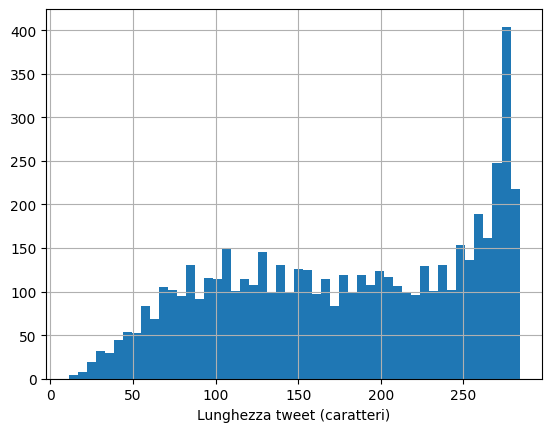

In [21]:
# Statistiche descrittive senza modificare il testo.
print(df_train['text_clean'].str.len().describe())
df_train['text_clean'].str.len().hist(bins=50)
plt.xlabel('Lunghezza tweet (caratteri)')
plt.show()

In [22]:
# Unique labels check
label_counts = df.groupby("text_clean")["label"].nunique()

conflicts = label_counts[label_counts > 1]

print(f"❌ Found {len(conflicts)} text(s) with contradictory labels :\n")
for text in conflicts.index:
    print(f"Text : {repr(text)}")

    associated_labels = df[df["text_clean"] == text]["label"].unique()
    print(f"Associated labels : {associated_labels}\n")



❌ Found 0 text(s) with contradictory labels :



#### Drop duplicates

In [23]:
df = df_train.copy()

if df.groupby("text_clean")["label"].nunique().gt(1).any():
    #raise ValueError("Some identical texts have conflicting labels.")
    df = df.drop_duplicates(subset="text_clean").reset_index(drop=True)


## Train/validation split

- we obtain the validation set by spliting the training data
- 10% will become validation
- seed set (42) for reproducibility

In [24]:
from sklearn.model_selection import train_test_split


train_df, val_df = train_test_split(
    df,
    test_size=0.10,
    random_state=42,
    stratify=df["label"],  # Preserve class proportions
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)

print(f"Train: {len(train_df)} | Validation: {len(val_df)}")
print("Train proportions:\n", train_df["label"].value_counts(normalize=True))
print("Validation proportions:\n", val_df["label"].value_counts(normalize=True))

Train: 5026 | Validation: 559
Train proportions:
 label
0    0.61739
1    0.38261
Name: proportion, dtype: float64
Validation proportions:
 label
0    0.617174
1    0.382826
Name: proportion, dtype: float64


In [25]:
train_df = load_split("train.csv")
val_df = load_split("validation.csv")
test_df = load_split('test.csv')


## Model and Tokenizer

In [26]:
# 1. Configuration
MODEL_NAME = (
    "m-polignano-uniba/"
    "bert_uncased_L-12_H-768_A-12_italian_alb3rt0"
)

SEED = 42
MAX_LENGTH = 256  # Tokens, not characters
OUTPUT_DIR = Path("outputs/alberto_raw_text") # output directory

set_seed(SEED)

In [27]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize(batch):
    return tokenizer(
        batch["text"], # Padding dinamico per ogni batch.
        truncation=True,
        max_length=MAX_LENGTH,

    )



/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.11M [00:00<?, ?B/s]

### Model loading (before dataset tokenization)

In [28]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    classifier_dropout=0.2,
    #hidden_dropout_prob=0.2,
    id2label={0: "NON_HATE", 1: "HATE"},
    label2id={"NON_HATE": 0, "HATE": 1},
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  740MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: m-polignano-uniba/bert_uncased_L-12_H-768_A-12_italian_alb3rt0
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialize

### make dataset

In [29]:
def make_dataset(frame):
    dataset = Dataset.from_pandas(frame[['text', 'labels']], preserve_index=False)
    return dataset.map(
        tokenize,
        batched=True,
        remove_columns=["text"],
    )


train_dataset = make_dataset(train_df)
val_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

Map:   0%|          | 0/5026 [00:00<?, ? examples/s]

Map:   0%|          | 0/559 [00:00<?, ? examples/s]

Map:   0%|          | 0/1400 [00:00<?, ? examples/s]

## Trainer and evaluation metrics

- best checkpoint is selected using validation macro-F1


In [30]:
# Evaluation metrics Accuracy, Precision, Recall and F1 score
def compute_metrics(eval_prediction):
    logits, labels = eval_prediction
    if isinstance(logits, tuple):
        logits = logits[0]

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        pos_label=1,
        zero_division=0,
    )

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels,
            predictions,
            labels=[0, 1],
            average="macro",
            zero_division=0,
        ),
        "hate_precision": precision,
        "hate_recall": recall,
        "hate_f1": f1,
    }


# Fine-tuning configuration
training_args = TrainingArguments(
    output_dir=str(OUTPUT_DIR),
    learning_rate=5e-6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=8,

    weight_decay=0.01,
    optim="adamw_torch",


    # chosen eval strategy for check the modelling before epoch completition since we have a small amount of training data
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,

    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,  #disk space clean
    logging_steps=50,
    report_to="none",
    seed=SEED, # seed for reproducibility
    data_seed=SEED,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    processing_class=tokenizer,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(
            early_stopping_patience=4,
            early_stopping_threshold=0.0,
        )]
        # Training stops after 4 evaluations without improved validation macro-F1 (about 300 steps).
)


# run training
trainer.train()



Step,Training Loss,Validation Loss,Accuracy,Macro F1,Hate Precision,Hate Recall,Hate F1
100,0.493790,0.378934,0.826476,0.812224,0.806283,0.719626,0.760494
200,0.289966,0.253718,0.906977,0.901215,0.885714,0.869159,0.877358
300,0.283940,0.231415,0.915921,0.910631,0.899522,0.878505,0.888889
400,0.290682,0.233455,0.917710,0.912772,0.896226,0.887850,0.892019
500,0.232900,0.312221,0.881932,0.879400,0.780303,0.962617,0.861925
600,0.224995,0.249552,0.921288,0.917810,0.869565,0.934579,0.900901
700,0.167842,0.265253,0.917710,0.913379,0.881818,0.906542,0.894009
800,0.193307,0.250624,0.914132,0.908980,0.891509,0.883178,0.887324
900,0.205411,0.303870,0.899821,0.896577,0.821138,0.943925,0.878261
1000,0.170708,0.290148,0.910555,0.906457,0.859649,0.915888,0.886878


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1000, training_loss=0.26315151262283326, metrics={'train_runtime': 342.4233, 'train_samples_per_second': 46.596, 'train_steps_per_second': 2.92, 'total_flos': 545374745550600.0, 'train_loss': 0.26315151262283326, 'epoch': 3.1746031746031744})

### Print best checkpoint results

In [31]:
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Best validation macro-F1:", trainer.state.best_metric)

Best checkpoint: outputs/alberto_raw_text/checkpoint-600
Best validation macro-F1: 0.9178095008955542


In [32]:
print("Classifier:", model.config.classifier_dropout)
print("Hidden:", model.config.hidden_dropout_prob)
print("Attention:", model.config.attention_probs_dropout_prob)

Classifier: 0.2
Hidden: 0.1
Attention: 0.1


## Prediction on test set and evaluation

In [33]:

test_output = trainer.predict(test_dataset)
test_predictions = np.argmax(test_output.predictions, axis=-1)

print("\nTest metrics:")
print(test_output.metrics)

print("\nClassification report:")
print(classification_report(
    test_df["labels"],
    test_predictions,
    labels=[0, 1],
    target_names=["NON_HATE", "HATE"],
    digits=4,
    zero_division=0,
))

print("\nConfusion matrix: rows=true labels, columns=predictions")
print(confusion_matrix(
    test_df["labels"],
    test_predictions,
    labels=[0, 1],
))


# Prediction example a new raw tweet
def predict_tweet(raw_text):
    inputs = tokenizer(
        raw_text,  # No preprocessing
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH,
    )
    inputs = {
        key: value.to(trainer.model.device)
        for key, value in inputs.items()
    }

    trainer.model.eval()
    with torch.no_grad():
        logits = trainer.model(**inputs).logits
        probabilities = torch.softmax(logits, dim=-1)[0]

    predicted_class = probabilities.argmax().item()

    return {
        "label": trainer.model.config.id2label[predicted_class],
        "probability_hate": probabilities[1].item(),
    }


print(predict_tweet(
    "@user_ab123 Non sono d'accordo con quello che dice Salvini."
))


Test metrics:
{'test_loss': 0.24984580278396606, 'test_accuracy': 0.9107142857142857, 'test_macro_f1': 0.9107142401603266, 'test_hate_precision': 0.9113018597997139, 'test_hate_recall': 0.91, 'test_hate_f1': 0.910650464617584, 'test_runtime': 6.0096, 'test_samples_per_second': 232.961, 'test_steps_per_second': 7.322}

Classification report:
              precision    recall  f1-score   support

    NON_HATE     0.9101    0.9114    0.9108       700
        HATE     0.9113    0.9100    0.9107       700

    accuracy                         0.9107      1400
   macro avg     0.9107    0.9107    0.9107      1400
weighted avg     0.9107    0.9107    0.9107      1400


Confusion matrix: rows=true labels, columns=predictions
[[638  62]
 [ 63 637]]
{'label': 'NON_HATE', 'probability_hate': 0.012471933849155903}


## Error analysis

### Save the predictions on val and test sets for doing an error analysis

In [34]:

# path directory
ERROR_DIR = Path(
    "/content/drive/MyDrive/master_unipa/alberto_raw_text_error_analysis"
)
ERROR_DIR.mkdir(parents=True, exist_ok=True)


def save_error_analysis(trainer, dataset, frame, split_name):

    output = trainer.predict(dataset, metric_key_prefix=split_name)

    logits = output.predictions
    if isinstance(logits, tuple):
        logits = logits[0]

    probabilities = torch.softmax(
        torch.tensor(logits), dim=-1
    )[:, 1].numpy()

    assert len(frame) == len(logits)
    np.testing.assert_array_equal(
        frame["labels"].to_numpy(),
        output.label_ids,
    )


    analysis = frame.copy().reset_index(drop=True)
    analysis["prediction"] = logits.argmax(axis=-1)
    analysis["probability_hate"] = probabilities
    analysis["correct"] = analysis["labels"].eq(analysis["prediction"])

    false_negatives = analysis[
        (analysis["labels"] == 1) & (analysis["prediction"] == 0)
    ].sort_values("probability_hate")

    false_positives = analysis[
        (analysis["labels"] == 0) & (analysis["prediction"] == 1)
    ].sort_values("probability_hate", ascending=False)

    for suffix, result in [
        ("predictions", analysis),
        ("false_negatives", false_negatives),
        ("false_positives", false_positives),
    ]:
        result.to_csv(
            ERROR_DIR / f"{split_name}_{suffix}.csv",
            index=False,
            encoding="utf-8-sig",
        )

    print(f"\n{split_name.upper()}")
    print(f"False negatives: {len(false_negatives)}")
    print(f"False positives: {len(false_positives)}")

    with pd.option_context("display.max_colwidth", None):
        print("\nFalse negatives — most confident mistakes first:")
        display(false_negatives.head(20))

        print("\nFalse positives — most confident mistakes first:")
        display(false_positives.head(20))

    return analysis, false_negatives, false_positives


val_analysis, val_fn, val_fp = save_error_analysis(
    trainer, val_dataset, val_df, "validation"
)

test_analysis, test_fn, test_fp = save_error_analysis(
    trainer, test_dataset, test_df, "test"
)

print(f"\nSaved CSV files to: {ERROR_DIR}")


VALIDATION
False negatives: 14
False positives: 30

False negatives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
352,"In #senato si sta votando ORA una vera e propria SANATORIA dei MISFATTI del #Governo #Conte. Chiedono la conversione in #Legge del #decreto del #25marzo. In parole povere, VOGLIONO PARARSI IL SEDERE SAPENDO D'AVER AGITO SENZA ALCUNA LEGITTIMAZIONE.\n@610058340653592 \n#20maggio",1,0,0.019502,False
449,Sarò sempre grato al #m5s. Far sparire #dibattista è un’opera di grande valore civico.,1,0,0.028482,False
475,"@629658163154054 Si, avrebbe potuto accadere altrove. Ma la prima regione infettata dell’Italia è la regione Lombardia sotto il governo #salvinivirus. E le altre no. Questo è un fatto. #coronavirusitalIa",1,0,0.030551,False
264,"@228609129215614 Se non riparte tutto non serve, cacciamo questo #governo, non si vince in modo pacifico e inevitabile che ci siano vittime ma è meglio morire lottando che subire questa dittatura. Prendiamo i loro #stipendi i loro beni i loro #vitalizi e facciamo #ripartire le attività.",1,0,0.031266,False
155,"cacciamo questo #governo compreso Mattarella, non si vince in modo pacifico e inevitabile che ci siano vittime ma è meglio morire lottando che subire questa dittatura. Prendiamo i loro #stipendi i loro beni i loro #vitalizi e facciamo #ripartire le attività. [URL]",1,0,0.032666,False
406,"Sono iscritto al #M5S dal 2010 e voterò NO per l'autorizzazione a procedere, non voglio più vedere nuovamente l'italia in mano al PD, Berlusconi, e altre bande di criminali\n#Diciotti #Saviano \n#17Febbraio #ottoemezzo #mezzorainpiu #m5s #BuonaDomenica #nonelarena #StaseraItalia",1,0,0.041406,False
556,"@868843245148057 #renzi, il tuo socio #Gozi avrà stappato una magnum 🥂🍾🥂, tra poco, il primo trombato di #Macron, potrà scaldare uno scranno a #Bruxelles e fare i suoi interessi.",1,0,0.068609,False
346,"@652473961427961 Su coraggio, e quanto prima diffondete la lista dei partecipanti (anche se sarà lunga e da dividere zona per zona)!\nCosì sapremo quali saranno i locali da frequentare anche dopo che ci saremo liberati dall'imbecille che si spaccia per #ministro!\n#ioapro #voiaprite #noiveniamo",1,0,0.097129,False
438,Ma La Palombella e stupida chiede #Fontana se per le riaperture e con #Salvini o #Letta #staseraitalia,1,0,0.122699,False
404,"""Grande giornalismo italiano "": @7805280724045 @445047337639856 dice che #m5scialtroni stia ripensando troppa presenza web detto anche da @662031690886848 - Latella un consiglio: pensa prima che sono incapaci e pericolosi. Ma tuo posto è salvo\n#ItaliaFinitoAnticorpi #Riformare",1,0,0.185203,False



False positives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
432,"@130425446247407 Anche San Marino, lì non hanno #speranza, ma #certezza.\n#speranzadimettiti\n#TachipirinaEVigileAttesa.\n#SantaInquisizioneCiFaUnaPippa",0,1,0.993662,False
108,"Salvini che ""screma"" i commenti negativi bloccando...significa che c'è un calo ed inesorabile calo dei consensi...\nTutto questo è bellissimo. \n#salvinicensuraitaliani \n#salviniblocca\n#salviniseiallafrutta\n#salvinivergognati \n#salvinicheraccontabufale",0,1,0.991911,False
18,"@804831429960458 Quel partito sembra aver recepito la lezione di un buffone del foro... quel tale che svelava a tutti come, per fare #politica, servano ""anima e cacciavite""!",0,1,0.988147,False
58,Senza vergogna.\n\n#Formigoni #vitalizi #ForzaItalia #regionelombardia #Fontana #fontanavattene #sanità #Salute #ASL #giustizia #sentenza #condanna #ingiustizia #vergogna #umiliazione #GovernodellaVergogna #pfizer #moderna #sputnik #JohnsonandJohnson #senzavergogna [URL],0,1,0.986442,False
6,@631840368218222 Ho pensato a #camilleri che sorrideva dal cielo un'oretta fa.\nGrazie Sicilia\n#salviniscappa,0,1,0.982698,False
458,La sfiga dei dinosauri fu che all'epoca non c'era Renzi a salvarli.\n\n#Renzi #renzivergognati #dinosauri #Albano #27agosto #OpenArms #Salvini,0,1,0.980843,False
35,"FORZA SIMO! Le figure di merda, quelle belle #pillon [URL]",0,1,0.974973,False
537,Quindi scopriamo oggi che un tentato reato non è reato.\n\nMa chi credete di pigliare per il culo?\n\n#Savoini\n\n#buzzfeed \n\n#salvini,0,1,0.973095,False
340,..#RENZI #BELLANOVA E ACCOLITI VARI..#TUTTIZITTI..? [URL],0,1,0.972090,False
508,"#Tommasi proclama lo sciopero dei #calciatori\nE quelli che stanno inseguendo un \npallone in #MilanGenoa #parmaspal e #SampVerona cosa sono,idraulici?\nImbianchini?\nPs. Non usate più il termine #pagliacci perché a breve l'associazione pagliacci potrebbe querelarvi per diffamazione.",0,1,0.968030,False



TEST
False negatives: 63
False positives: 62

False negatives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
257,"Ieri in Senato si discuteva della questione #Ilva, il senatore #salvini era assente in quanto a #Verona per la #FieraCavalli.\nC'è un padiglione dedicato agli asini.",1,0,0.010318,False
235,"Da radio Capital. ""Sulla manovra confermato il deficit al 2,2% per il 2020"".\nA Bruxelles, sui media italiani tutti zitti.\nUn anno fa hanno frantumato i c*glioni per il 2,04%.\nHa letto male lo speaker oppure lo stato si è rimesso a 90°?\n#deficit #Conte #m5spd\n#giallorosso",1,0,0.016876,False
321,@unknown Contro il #m5stelle c'è una #associazione a #delinquere di stampo giornalistico. cit @185232423305451,1,0,0.017869,False
102,@unknown #pd #sx e #m5s stanno lavorando per la nostra sostituzione etnica con gli africani.\n\nIl 26 maggio i sovranisti vinceranno per legittima difesa! #votoLega,1,0,0.021270,False
743,"Covid, Vittorio Sgarbi contro Roberto Speranza: ""Responsabili di disagio e morte, finirete in tribunale""\n[URL]",1,0,0.023933,False
365,@621514259604154 Ma figurati.. #m5s #pd hanno fatto in modo di arrivare a PD al governo già dal #4marzo\n Ringraziamo il burattinaio #mattarella e i suoi mandanti,1,0,0.026229,False
1259,#25aprile \nIl giorno dei vigliacchi🕷☭,1,0,0.026582,False
560,La #Bonino presenta una mozione di sfiducia perchè #Bonafede mette dentro troppi criminali\n\nIl CDX presenta una mozione di sfiducia perchè #Bonafede li mette fuori\n\nLa lega voterà entrambe le mozioni\n\nVince la Lega per manifesta stupidità \n\n#Renzi #Meloni\n#decretorilancio,1,0,0.028594,False
822,@657509535824434 @536559930021830 Vediamo in quanti firmano per mandare te a lavorare dopo 25 anni di nullafacenza? #petizionemeloniacasa #giorgiameloni #petizione #politici,1,0,0.034341,False
154,"Al netto di ciò che penso della #crisidigoverno, trovo osceno buttarla in caciara col rischio di arrivare a #leggedibilancio in condizioni di estrema fragilità nei confronti dell'Europa scaricando sugli italiani il peso dell’incompetenza e della malafede di questa classe politica",1,0,0.038214,False



False positives — most confident mistakes first:


,text,labels,prediction,probability_hate,correct
938,#LaTtualità #Draghi #GovernoDraghi #SalviniPagliaccio #Salvini #riaperture #DecretoRiaperture #DecretoCovid #Coprifuoco aprire la foto! [URL],0,1,0.996573,False
1073,"Ma si, continuiamo a non curare i malati... \n#SperanzaVattene [URL]",0,1,0.993542,False
336,"#dincà ha ragione...la gente non è stupida, ma nel capire il gioco delle tre carte del #pdm5s Buffoni! Altroché #salvini vittima! #tagadala7",0,1,0.990932,False
572,"A tutti i rancorosi che rilanciano #salviniCIALTRONE, ma che razza di vita frustrante hanno per vomitare tanto livore, poi sopratutto contro un'esponente di minoranza.\nChi è ossessionato dai #49milioni di @943206476637778, si informino dei 81,6 milioni dell'Unità che pagherà.",0,1,0.987832,False
508,"#Report #RenzoRosso #Quartarepubblica \nMascherine prezzo fissato 0,50\nIl Manzoni scrisse' che durante la peste ci fu il prezzo fissato del PANE, ma siccome a quel prezzo nessuno lo vendeva ci fu una rivoluzione e l' assalto ai forni\nSONO COSI' IGNORANTI questi del #contedimettiti",0,1,0.983829,False
146,@unknown @unknown Dimostrazione che questo.governo usa le cose che succedono e le strumentalizza a suo modo per avere voti #SalviniDimettiti #salvinivergognati #sequestoeunministro,0,1,0.981447,False
733,"Qualcuno avvisi la #Lega e #Salvini, anche la mia vicina di casa da la colpa di tutto a #Speranza, almeno possono rifare un twit contro di lui.\n#Lega #Salvinivergognati [URL]",0,1,0.981263,False
290,"la faccia acida della #meli che sprizza #odio sputacchiando domande preparate a tavolino, la #berlinguer che agita le mani sudaticcie non hanno prezzo\n\n#salvininonmollare \n#cartabianca",0,1,0.981260,False
300,"La moglie del proprietario del Papeete candidata con Borgonzoni in Emilia Romagna.\nIl proprietario è già eletto al parlamento europeo.\n\nQuanto ci sono costati un inno, due cubiste e qualche mojito!\n#salvinipromettecose\n#salvinivergognati",0,1,0.979521,False
998,#Drittoerovescio Italia tra #coprifuoco e #lockdown ... #Speranzadimettiti [URL],0,1,0.979011,False



Saved CSV files to: /content/drive/MyDrive/master_unipa/alberto_raw_text_error_analysis
